# Proyek Analisis Data: Air Quality Dataset (PRSA Beijing)
- **Nama:** Sandi Ardi Prayitno
- **Email:** ds284b6y1625@student.devacademy.id
- **ID Dicoding:** DS284B6Y1625

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Stasiun pemantauan mana (dari 12 stasiun) yang memiliki rata-rata konsentrasi PM2.5 tertinggi dan terendah, serta berapa persen hari di setiap stasiun yang melampaui ambang batas harian standar kualitas udara China (75 µg/m³) selama periode 1 Maret 2013 – 28 Februari 2017?
- **Pertanyaan 2:** Pada bulan dan jam berapa rata-rata konsentrasi PM2.5 mencapai titik tertinggi dan terendah sepanjang tiga tahun kalender penuh 2014–2016, dan seberapa besar perubahan rata-rata tahunannya dari 2014 ke 2016?
- **Pertanyaan 3:** Dari variabel cuaca (suhu, tekanan udara, titik embun, curah hujan, kecepatan angin), variabel mana yang memiliki korelasi paling kuat dengan PM2.5 harian, dan dari arah angin mana PM2.5 rata-rata paling tinggi, selama periode 1 Maret 2013 – 28 Februari 2017?

## Import Semua Packages/Library yang Digunakan

In [2]:
import glob
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Palet warna konsisten untuk seluruh visualisasi
C_HIGH = "#C0392B"   # merah  -> nilai tinggi / buruk
C_LOW = "#1B7F8C"    # teal   -> nilai rendah / baik
C_NEUTRAL = "#B8BEC6"  # abu-abu -> nilai lainnya

## Data Wrangling

### Gathering Data

#### Load df  stasiun pemantau

Dataset terdiri dari **12 file CSV** (satu file per stasiun) dengan struktur kolom yang sama. Seluruh file dimuat dan digabung menjadi satu DataFrame `air_df`.

Keterangan kolom: `No` (nomor baris), `year/month/day/hour` (waktu), `PM2.5`, `PM10`, `SO2`, `NO2`, `CO`, `O3` (konsentrasi polutan), `TEMP` (suhu, °C), `PRES` (tekanan, hPa), `DEWP` (titik embun, °C), `RAIN` (curah hujan, mm), `wd` (arah angin), `WSPM` (kecepatan angin, m/s), dan `station` (nama stasiun).

In [5]:
DATA_DIR = r"C:\Users\sandi\Downloads\submission\data"
search_path = os.path.join(DATA_DIR, "**", "PRSA_Data_*.csv")

files = sorted(glob.glob(search_path, recursive=True))

print(f"Jumlah file stasiun ditemukan: {len(files)}\n")

df_list = []
for f in files:
    temp = pd.read_csv(f)
    
    # Menambahkan lokasi file
    temp['lokasi_file'] = f 
    
    print(f"{os.path.basename(f):55s} -> {temp.shape[0]:,} baris, {temp.shape[1]} kolom")
    df_list.append(temp)

if not df_list:
    raise FileNotFoundError(
        "File PRSA_Data_*.csv tidak ditemukan. Pastikan dataset zip sudah diekstrak."
    )

air_df = pd.concat(df_list, ignore_index=True)
print("\nUkuran gabungan seluruh stasiun:", air_df.shape)
air_df.head()

Jumlah file stasiun ditemukan: 12

PRSA_Data_Aotizhongxin_20130301-20170228.csv            -> 35,064 baris, 19 kolom
PRSA_Data_Changping_20130301-20170228.csv               -> 35,064 baris, 19 kolom
PRSA_Data_Dingling_20130301-20170228.csv                -> 35,064 baris, 19 kolom
PRSA_Data_Dongsi_20130301-20170228.csv                  -> 35,064 baris, 19 kolom
PRSA_Data_Guanyuan_20130301-20170228.csv                -> 35,064 baris, 19 kolom
PRSA_Data_Gucheng_20130301-20170228.csv                 -> 35,064 baris, 19 kolom
PRSA_Data_Huairou_20130301-20170228.csv                 -> 35,064 baris, 19 kolom
PRSA_Data_Nongzhanguan_20130301-20170228.csv            -> 35,064 baris, 19 kolom
PRSA_Data_Shunyi_20130301-20170228.csv                  -> 35,064 baris, 19 kolom
PRSA_Data_Tiantan_20130301-20170228.csv                 -> 35,064 baris, 19 kolom
PRSA_Data_Wanliu_20130301-20170228.csv                  -> 35,064 baris, 19 kolom
PRSA_Data_Wanshouxigong_20130301-20170228.csv           -> 35,0

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,lokasi_file
0,1,2013,3,1,0,4.00,4.00,4.00,7.00,300.00,77.00,-0.70,"1,023.00",-18.80,0.00,NNW,4.40,Aotizhongxin,C:\Users\sandi\Downloads\submission\data\PRSA_...
1,2,2013,3,1,1,8.00,8.00,4.00,7.00,300.00,77.00,-1.10,"1,023.20",-18.20,0.00,N,4.70,Aotizhongxin,C:\Users\sandi\Downloads\submission\data\PRSA_...
2,3,2013,3,1,2,7.00,7.00,5.00,10.00,300.00,73.00,-1.10,"1,023.50",-18.20,0.00,NNW,5.60,Aotizhongxin,C:\Users\sandi\Downloads\submission\data\PRSA_...
3,4,2013,3,1,3,6.00,6.00,11.00,11.00,300.00,72.00,-1.40,"1,024.50",-19.40,0.00,NW,3.10,Aotizhongxin,C:\Users\sandi\Downloads\submission\data\PRSA_...
4,5,2013,3,1,4,3.00,3.00,12.00,12.00,300.00,72.00,-2.00,"1,025.20",-19.50,0.00,N,2.00,Aotizhongxin,C:\Users\sandi\Downloads\submission\data\PRSA_...


**Insight:** (Opsional)
- Terdapat 12 stasiun dengan jumlah baris yang identik (35.064 baris per stasiun = 1.461 hari x 24 jam), sehingga total data gabungan adalah 420.768 baris x 18 kolom.
- Struktur kolom seragam di semua file, sehingga penggabungan dengan `pd.concat` aman dilakukan.
- Kolom waktu masih terpisah menjadi `year`, `month`, `day`, `hour`; perlu digabung menjadi satu kolom `datetime` pada tahap selanjutnya.

### Assessing Data

#### Memeriksa tipe data dan struktur umum

In [6]:
air_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 19 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   No           420768 non-null  int64  
 1   year         420768 non-null  int64  
 2   month        420768 non-null  int64  
 3   day          420768 non-null  int64  
 4   hour         420768 non-null  int64  
 5   PM2.5        412029 non-null  float64
 6   PM10         414319 non-null  float64
 7   SO2          411747 non-null  float64
 8   NO2          408652 non-null  float64
 9   CO           400067 non-null  float64
 10  O3           407491 non-null  float64
 11  TEMP         420370 non-null  float64
 12  PRES         420375 non-null  float64
 13  DEWP         420365 non-null  float64
 14  RAIN         420378 non-null  float64
 15  wd           418946 non-null  object 
 16  WSPM         420450 non-null  float64
 17  station      420768 non-null  object 
 18  lokasi_file  420768 non-

#### Identifying missing value

In [7]:
missing = pd.DataFrame({
    "jumlah_missing": air_df.isna().sum(),
    "persen_missing": air_df.isna().mean() * 100,
})
missing = missing[missing["jumlah_missing"] > 0].sort_values("jumlah_missing", ascending=False)
missing

,jumlah_missing,persen_missing
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


In [8]:
# Tambahkan kolom datetime (diperlukan untuk menilai urutan waktu & kelengkapan)
air_df["datetime"] = pd.to_datetime(air_df[["year", "month", "day", "hour"]])

def longest_gap(s):
    """Panjang blok jam berturut-turut yang kosong terpanjang."""
    na = s.isna().astype(int)
    grp = (na.diff() != 0).cumsum()
    return na.groupby(grp).sum().max()

gap_summary = air_df.sort_values(["station", "datetime"]).groupby("station")["PM2.5"].apply(longest_gap)
print("Blok jam kosong terpanjang pada PM2.5 per stasiun:")
print(gap_summary.to_string())

Blok jam kosong terpanjang pada PM2.5 per stasiun:
station
Aotizhongxin     343
Changping        167
Dingling          72
Dongsi            58
Guanyuan          71
Gucheng           54
Huairou          208
Nongzhanguan      56
Shunyi           197
Tiantan           24
Wanliu            23
Wanshouxigong     43


#### Identifying duplicate data

In [9]:
print("Baris duplikat (seluruh kolom)        :", air_df.duplicated().sum())
print("Duplikat kombinasi station + datetime :", air_df.duplicated(subset=["station", "datetime"]).sum())
print("\nRentang waktu data:", air_df["datetime"].min(), "s.d.", air_df["datetime"].max())
print("\nJumlah baris per stasiun (seharusnya 35.064 = 1.461 hari x 24 jam):")
print(air_df.groupby("station").size().unique())

Baris duplikat (seluruh kolom)        : 0
Duplikat kombinasi station + datetime : 0

Rentang waktu data: 2013-03-01 00:00:00 s.d. 2017-02-28 23:00:00

Jumlah baris per stasiun (seharusnya 35.064 = 1.461 hari x 24 jam):
[35064]


#### Identifying invalid / inconsistent value

In [10]:
polutan = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]

print("Nilai negatif pada polutan:", int((air_df[polutan] < 0).sum().sum()))
print("Nilai RAIN negatif        :", int((air_df["RAIN"] < 0).sum()))

# PM2.5 adalah bagian dari PM10, sehingga PM10 tidak mungkin lebih kecil daripada PM2.5
tidak_konsisten = air_df["PM10"] < air_df["PM2.5"]
print(f"\nBaris dengan PM10 < PM2.5 (tidak logis): {tidak_konsisten.sum():,} "
      f"({tidak_konsisten.mean()*100:.2f}% dari seluruh baris)")

print("\nKategori unik arah angin (wd):")
print(sorted(air_df["wd"].dropna().unique()))

Nilai negatif pada polutan: 0
Nilai RAIN negatif        : 0

Baris dengan PM10 < PM2.5 (tidak logis): 21,312 (5.07% dari seluruh baris)

Kategori unik arah angin (wd):
['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']


#### Identifying outlier

In [11]:
num_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

def count_iqr_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outlier_df = pd.DataFrame({
    "jumlah_outlier_IQR": air_df[num_cols].apply(count_iqr_outlier),
    "persen": air_df[num_cols].apply(count_iqr_outlier) / len(air_df) * 100,
    "min": air_df[num_cols].min(),
    "median": air_df[num_cols].median(),
    "max": air_df[num_cols].max(),
})
print(outlier_df)
print("\nJumlah baris PM2.5 >= 900 µg/m³:", int((air_df["PM2.5"] >= 900).sum()))

       jumlah_outlier_IQR  persen    min   median       max
PM2.5               19142    4.55   2.00    55.00    999.00
PM10                14658    3.48   2.00    82.00    999.00
SO2                 35566    8.45   0.29     7.00    500.00
NO2                  7021    1.67   1.03    43.00    290.00
CO                  28054    6.67 100.00   900.00 10,000.00
O3                  16599    3.94   0.21    45.00  1,071.00
TEMP                    0    0.00 -19.90    14.50     41.60
PRES                    0    0.00 982.40 1,010.40  1,042.80
DEWP                    0    0.00 -43.40     3.10     29.10
RAIN                16520    3.93   0.00     0.00     72.50
WSPM                23079    5.48   0.00     1.40     13.20

Jumlah baris PM2.5 >= 900 µg/m³: 3


**Steps to Take:**
- **Missing value:** PM2.5 hilang 8.739 baris (2,1%), CO hilang 4,9%, dan kolom lain 0,1–3,2%. Sebagian besar blok kosong hanya 1–2 jam berturut-turut (contoh pada stasiun Aotizhongxin), tetapi ada blok panjang (hingga 343 jam pada satu stasiun). Tindakan: **interpolasi linear per stasiun dengan batas maksimal 6 jam** untuk kolom numerik dan *forward/backward fill* (maks. 6 jam) untuk arah angin `wd`. Blok yang lebih panjang tidak diisi agar tidak menciptakan data palsu.
- **Duplicate data:** tidak ditemukan duplikat, sehingga tidak diperlukan penghapusan.
- **Invalid/inconsistent value:** tidak ada nilai negatif, tetapi terdapat 21.312 baris dengan `PM10 < PM2.5` yang secara fisik tidak mungkin. Tindakan: tandai dengan kolom `flag_pm_inconsistent`, lalu ubah nilai `PM10` pada baris tersebut menjadi NaN (kemudian diinterpolasi). Analisis utama memakai PM2.5 sehingga PM2.5 dipertahankan.
- **Outlier:** terdapat banyak outlier menurut IQR pada PM2.5, PM10, CO, SO2, RAIN, dan WSPM, namun nilai-nilai ini merupakan **episode polusi dan cuaca nyata** (bukan kesalahan input). Tindakan: **outlier dipertahankan** karena justru menjadi fokus analisis polusi ekstrem. Agar ringkasan tidak terdistorsi, analisis memakai rata-rata harian dan median sebagai pembanding.
- **Tipe data:** kolom waktu dipecah menjadi 4 kolom; tindakan: gabungkan menjadi `datetime`, urutkan per stasiun, lalu buat agregasi harian (minimal 18 jam valid per hari).

**Insight:** (Opsional)
- Kualitas data secara umum baik: tidak ada duplikat, tidak ada nilai negatif, dan setiap stasiun memiliki rentang waktu yang lengkap (tidak ada jam yang hilang dari deret waktu).
- Masalah utama adalah *missing value* (terbanyak pada CO dan NO2) serta ketidakkonsistenan PM10 < PM2.5 yang mengindikasikan galat pengukuran sensor.
- Nilai PM2.5 maksimum 999 µg/m³ muncul hanya pada 3 baris; nilai ini adalah batas atas pembacaan alat sehingga dicatat sebagai keterbatasan data, bukan dihapus.

### Cleaning Data

#### Fixing datetime, ordering, dan inconsistent value (PM10 < PM2.5)

In [12]:
clean_df = air_df.copy()

# 1) Urutkan per stasiun berdasarkan waktu (diperlukan untuk interpolasi deret waktu)
clean_df = clean_df.sort_values(["station", "datetime"]).reset_index(drop=True)
clean_df["date"] = clean_df["datetime"].dt.normalize()

# 2) Tandai & koreksi PM10 yang lebih kecil dari PM2.5
mask_inkonsisten = clean_df["PM10"] < clean_df["PM2.5"]
clean_df["flag_pm_inconsistent"] = mask_inkonsisten
clean_df.loc[mask_inkonsisten, "PM10"] = np.nan

print("Baris PM10 yang dikoreksi menjadi NaN:", int(mask_inkonsisten.sum()))

Baris PM10 yang dikoreksi menjadi NaN: 21312


#### Fixing missing value

In [13]:
print("Total missing sebelum imputasi (kolom numerik):", int(clean_df[num_cols].isna().sum().sum()))

# Interpolasi linear per stasiun, maksimal 6 jam berturut-turut
clean_df[num_cols] = (
    clean_df.groupby("station")[num_cols]
    .transform(lambda s: s.interpolate(method="linear", limit=6, limit_direction="both"))
)

# Arah angin (kategorikal): isi dengan nilai terdekat, maksimal 6 jam
clean_df["wd"] = clean_df.groupby("station")["wd"].transform(lambda s: s.ffill(limit=6).bfill(limit=6))

print("Total missing sesudah imputasi  (kolom numerik):", int(clean_df[num_cols].isna().sum().sum()))
print("Missing arah angin sesudah imputasi            :", int(clean_df["wd"].isna().sum()))
clean_df[num_cols + ["wd"]].isna().sum()

Total missing sebelum imputasi (kolom numerik): 93517
Total missing sesudah imputasi  (kolom numerik): 28903
Missing arah angin sesudah imputasi            : 1


PM2.5     2471
PM10      4502
SO2       2977
NO2       4467
CO       10458
O3        4028
TEMP         0
PRES         0
DEWP         0
RAIN         0
WSPM         0
wd           1
dtype: int64

#### Membuat agregasi harian (daily_df)

Analisis dilakukan pada **rata-rata harian per stasiun** karena ambang batas standar kualitas udara (75 µg/m³) didefinisikan untuk rata-rata 24 jam. Hari dengan kurang dari 18 jam data valid dianggap tidak representatif sehingga nilainya dikosongkan (NaN). Arah angin harian diambil dari modus (arah yang paling sering muncul).

In [14]:
grp = clean_df.groupby(["station", "date"])
daily_df = grp[num_cols].mean()
daily_df["n_jam_valid"] = grp["PM2.5"].count()
daily_df["wd"] = grp["wd"].agg(lambda s: s.mode().iloc[0] if s.notna().any() else np.nan)
daily_df = daily_df.reset_index()

# Hari dengan < 18 jam data valid dianggap tidak representatif
daily_df.loc[daily_df["n_jam_valid"] < 18, num_cols] = np.nan
daily_df["year"] = daily_df["date"].dt.year
daily_df["month"] = daily_df["date"].dt.month

print("Ukuran daily_df:", daily_df.shape)
print(f"Persentase hari tanpa nilai PM2.5 valid: {daily_df['PM2.5'].isna().mean()*100:.2f}%")
daily_df.head()

Ukuran daily_df: (17532, 17)
Persentase hari tanpa nilai PM2.5 valid: 0.66%


,station,date,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,n_jam_valid,wd,year,month
0,Aotizhongxin,2013-03-01,7.12,10.75,11.71,22.58,429.17,63.88,1.39,"1,026.88",-18.75,0.00,3.25,24,N,2013,3
1,Aotizhongxin,2013-03-02,30.75,42.08,36.62,66.67,824.92,29.75,0.62,"1,026.85",-15.94,0.00,1.48,24,NE,2013,3
2,Aotizhongxin,2013-03-03,76.92,120.54,61.29,81.00,"1,620.62",19.12,5.57,"1,014.61",-12.32,0.00,1.66,24,NNE,2013,3
3,Aotizhongxin,2013-03-04,22.71,44.58,22.85,46.19,606.25,53.75,9.96,"1,017.65",-11.68,0.00,2.40,24,N,2013,3
4,Aotizhongxin,2013-03-05,148.88,183.79,93.88,132.83,"2,357.96",68.46,6.29,"1,010.90",-7.52,0.00,1.13,24,NE,2013,3


#### Menyimpan data bersih untuk dashboard

- `dashboard/main_data.csv` : data harian per stasiun (dipakai dashboard).
- `dashboard/hourly_pattern.csv` : rata-rata PM2.5 per stasiun x tahun x bulan x jam (dipakai untuk pola per jam di dashboard, ukurannya jauh lebih kecil dibanding data per jam penuh).

In [15]:
os.makedirs("dashboard", exist_ok=True)

daily_df.to_csv("dashboard/main_data.csv", index=False)

hourly_pattern = (
    clean_df.groupby(["station", "year", "month", "hour"], as_index=False)["PM2.5"].mean().round(2)
)
hourly_pattern.to_csv("dashboard/hourly_pattern.csv", index=False)

print("main_data.csv       :", daily_df.shape)
print("hourly_pattern.csv  :", hourly_pattern.shape)

main_data.csv       : (17532, 17)
hourly_pattern.csv  : (13824, 5)


**Insight:** (Opsional)
- Setelah interpolasi terbatas (maks. 6 jam), sisa nilai kosong PM2.5 tinggal sebagian kecil dan hanya berasal dari blok kekosongan panjang yang memang sebaiknya tidak diisi.
- Setelah agregasi harian dengan syarat minimal 18 jam valid, hanya sekitar 0,7% hari per stasiun yang tidak memiliki nilai PM2.5, sehingga hasil analisis tetap representatif.
- 17.532 baris harian (12 stasiun x 1.461 hari) siap dipakai untuk EDA dan dashboard.

## Exploratory Data Analysis (EDA)

### Explore ringkasan statistik data harian

In [16]:
daily_df[["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]].describe().T

,count,mean,std,min,25%,50%,75%,max
PM2.5,"17,416.00",79.89,69.49,3.00,30.12,60.54,107.57,567.42
PM10,"17,403.00",106.21,75.88,4.83,49.67,88.96,139.34,584.70
SO2,"17,375.00",15.90,18.47,0.50,3.79,8.96,20.38,160.02
NO2,"17,321.00",50.56,28.24,2.00,30.42,45.62,65.00,205.38
CO,"17,105.00","1,234.62",993.30,100.00,612.50,950.00,"1,491.67","9,402.08"
O3,"17,340.00",56.98,38.91,0.25,25.62,51.45,81.50,526.42
TEMP,"17,416.00",13.50,10.84,-15.68,3.00,14.95,23.46,32.37
PRES,"17,416.00","1,010.78",10.27,985.79,"1,002.35","1,010.55","1,018.95","1,041.02"
DEWP,"17,416.00",2.45,13.54,-33.02,-9.24,2.72,14.99,27.62
RAIN,"17,416.00",0.06,0.33,0.00,0.00,0.00,0.00,11.11


## Visualization & Explanatory Analysis

### Pertanyaan 1: 
Stasiun pemantauan mana (dari 12 stasiun) yang memiliki rata-rata konsentrasi PM2.5 tertinggi dan terendah, serta berapa persen hari di setiap stasiun yang melampaui ambang batas harian standar kualitas udara China (75 µg/m³) selama periode 1 Maret 2013 – 28 Februari 2017?

In [17]:
BATAS_HARIAN = 75   # µg/m³, rata-rata 24 jam
BATAS_TAHUNAN = 35  # µg/m³, rata-rata tahunan

pm_daily = daily_df.dropna(subset=["PM2.5"]).copy()
pm_daily["melampaui"] = pm_daily["PM2.5"] > BATAS_HARIAN

station_stats = pm_daily.groupby("station").agg(
    mean_pm25=("PM2.5", "mean"),
    median_pm25=("PM2.5", "median"),
    max_pm25=("PM2.5", "max"),
    hari_valid=("PM2.5", "count"),
    hari_melampaui=("melampaui", "sum"),
)
station_stats["persen_melampaui"] = station_stats["hari_melampaui"] / station_stats["hari_valid"] * 100
station_stats = station_stats.sort_values("mean_pm25", ascending=False)
station_stats

,mean_pm25,median_pm25,max_pm25,hari_valid,hari_melampaui,persen_melampaui
station,,,,,,
Dongsi,86.11,65.88,567.42,1448,628,43.37
Nongzhanguan,85.22,63.56,516.06,1458,625,42.87
Wanshouxigong,84.94,64.29,536.62,1455,621,42.68
Gucheng,84.02,65.50,519.75,1456,626,42.99
Wanliu,83.47,64.60,481.29,1460,625,42.81
Guanyuan,83.01,63.83,536.08,1455,616,42.34
Aotizhongxin,82.99,63.12,512.29,1439,610,42.39
Tiantan,82.02,62.56,499.33,1460,603,41.30
Shunyi,79.78,60.83,514.62,1445,593,41.04


In [18]:
print(f"Rata-rata PM2.5 seluruh stasiun        : {pm_daily['PM2.5'].mean():.1f} µg/m³")
print(f"Stasiun tertinggi : {station_stats.index[0]} ({station_stats['mean_pm25'].iloc[0]:.1f} µg/m³)")
print(f"Stasiun terendah  : {station_stats.index[-1]} ({station_stats['mean_pm25'].iloc[-1]:.1f} µg/m³)")
selisih = station_stats['mean_pm25'].iloc[0] / station_stats['mean_pm25'].iloc[-1] - 1
print(f"Selisih tertinggi vs terendah           : {selisih*100:.1f}%")
print(f"Persentase hari melampaui {BATAS_HARIAN} µg/m³ (gabungan) : {pm_daily['melampaui'].mean()*100:.1f}%")

Rata-rata PM2.5 seluruh stasiun        : 79.9 µg/m³
Stasiun tertinggi : Dongsi (86.1 µg/m³)
Stasiun terendah  : Dingling (66.3 µg/m³)
Selisih tertinggi vs terendah           : 29.9%
Persentase hari melampaui 75 µg/m³ (gabungan) : 40.4%


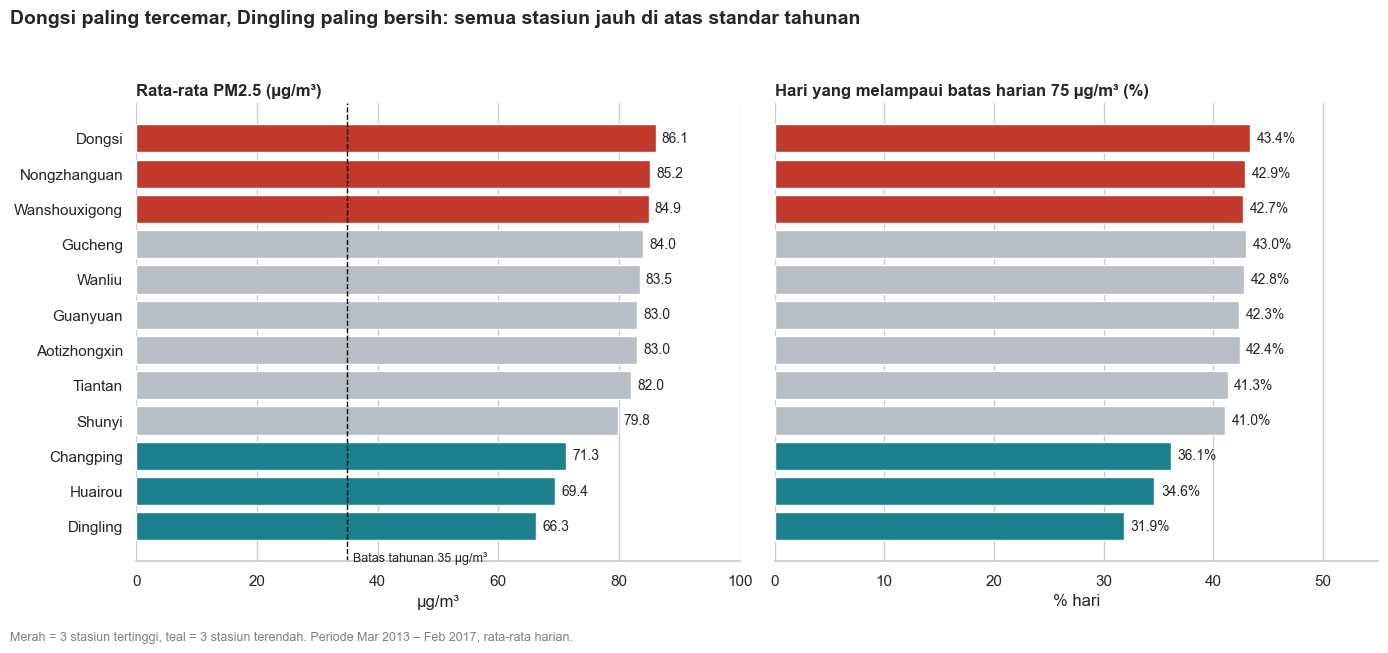

In [19]:
plot_df = station_stats.sort_values("mean_pm25", ascending=True)   # tertinggi tampil di atas
n = len(plot_df)
colors = [C_LOW if i < 3 else (C_HIGH if i >= n - 3 else C_NEUTRAL) for i in range(n)]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)

# Panel kiri: rata-rata PM2.5
ax = axes[0]
ax.barh(plot_df.index, plot_df["mean_pm25"], color=colors)
for y, v in enumerate(plot_df["mean_pm25"]):
    ax.text(v + 1, y, f"{v:.1f}", va="center", fontsize=10)
ax.axvline(BATAS_TAHUNAN, color="black", linestyle="--", linewidth=1)
ax.text(BATAS_TAHUNAN + 1, -0.9, f"Batas tahunan {BATAS_TAHUNAN} µg/m³", fontsize=9, va="center")
ax.set_title("Rata-rata PM2.5 (µg/m³)", loc="left", fontsize=12, fontweight="bold")
ax.set_xlabel("µg/m³")
ax.set_xlim(0, 100)

# Panel kanan: persentase hari melampaui batas harian
ax = axes[1]
ax.barh(plot_df.index, plot_df["persen_melampaui"], color=colors)
for y, v in enumerate(plot_df["persen_melampaui"]):
    ax.text(v + 0.6, y, f"{v:.1f}%", va="center", fontsize=10)
ax.set_title(f"Hari yang melampaui batas harian {BATAS_HARIAN} µg/m³ (%)", loc="left", fontsize=12, fontweight="bold")
ax.set_xlabel("% hari")
ax.set_xlim(0, 55)

for a in axes:
    a.grid(axis="y", visible=False)
    sns.despine(ax=a, left=True)

fig.suptitle("Dongsi paling tercemar, Dingling paling bersih: semua stasiun jauh di atas standar tahunan",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, 0.01, "Merah = 3 stasiun tertinggi, teal = 3 stasiun terendah. Periode Mar 2013 – Feb 2017, rata-rata harian.",
         fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Pertanyaan 2:
Pada bulan dan jam berapa rata-rata konsentrasi PM2.5 mencapai titik tertinggi dan terendah sepanjang tiga tahun kalender penuh 2014–2016, dan seberapa besar perubahan rata-rata tahunannya dari 2014 ke 2016?

In [20]:
# Hanya tahun kalender penuh 2014-2016 agar setiap bulan terwakili sama banyak
full_years = pm_daily[pm_daily["year"].isin([2014, 2015, 2016])]

monthly_mean = full_years.groupby("month")["PM2.5"].mean()
print("Rata-rata PM2.5 per bulan (2014-2016):")
print(monthly_mean.round(1).to_string())

yearly_mean = full_years.groupby("year")["PM2.5"].mean()
print("\nRata-rata PM2.5 per tahun:")
print(yearly_mean.round(1).to_string())
print(f"\nPerubahan 2014 -> 2016: {(yearly_mean[2016]/yearly_mean[2014]-1)*100:.1f}%")

Rata-rata PM2.5 per bulan (2014-2016):
month
1     87.10
2     95.90
3     91.20
4     76.60
5     57.10
6     57.90
7     73.00
8     51.00
9     56.30
10    91.80
11    99.80
12   113.10

Rata-rata PM2.5 per tahun:
year
2014   86.30
2015   79.40
2016   71.90

Perubahan 2014 -> 2016: -16.8%


In [21]:
# Pola per jam dihitung dari data per jam yang sudah dibersihkan
hourly_mean = clean_df[clean_df["year"].isin([2014, 2015, 2016])].groupby("hour")["PM2.5"].mean()
print("Rata-rata PM2.5 per jam (2014-2016):")
print(hourly_mean.round(1).to_string())
print(f"\nJam tertinggi: {hourly_mean.idxmax():02d}:00 ({hourly_mean.max():.1f} µg/m³)")
print(f"Jam terendah : {hourly_mean.idxmin():02d}:00 ({hourly_mean.min():.1f} µg/m³)")

Rata-rata PM2.5 per jam (2014-2016):
hour
0    86.70
1    86.20
2    84.30
3    81.80
4    79.10
5    76.20
6    73.90
7    73.00
8    74.10
9    75.80
10   77.00
11   77.00
12   76.30
13   75.90
14   75.00
15   73.70
16   73.50
17   74.60
18   77.00
19   81.30
20   85.30
21   87.50
22   87.90
23   87.70

Jam tertinggi: 22:00 (87.9 µg/m³)
Jam terendah : 07:00 (73.0 µg/m³)


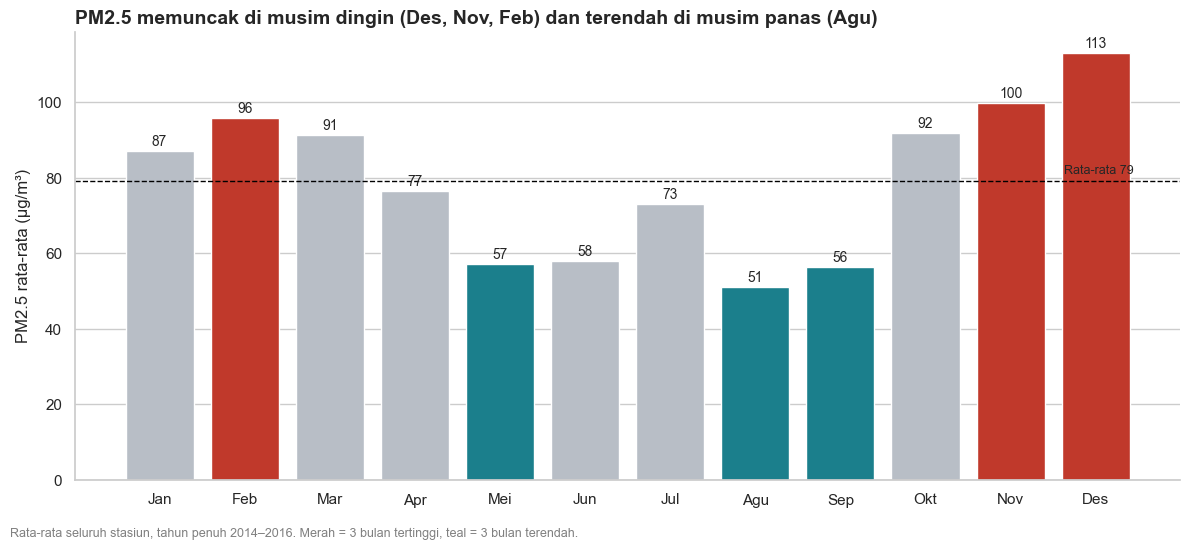

In [22]:
bulan_label = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
mm = monthly_mean.sort_index()
rank = mm.rank(ascending=False)
colors_m = [C_HIGH if r <= 3 else (C_LOW if r >= 10 else C_NEUTRAL) for r in rank]

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.bar(bulan_label, mm.values, color=colors_m)
for x, v in enumerate(mm.values):
    ax.text(x, v + 1.5, f"{v:.0f}", ha="center", fontsize=10)
ax.axhline(mm.mean(), color="black", linestyle="--", linewidth=1)
ax.text(11.45, mm.mean() + 2, f"Rata-rata {mm.mean():.0f}", ha="right", fontsize=9)
ax.set_ylabel("PM2.5 rata-rata (µg/m³)")
ax.set_title("PM2.5 memuncak di musim dingin (Des, Nov, Feb) dan terendah di musim panas (Agu)",
             loc="left", fontsize=14, fontweight="bold")
ax.grid(axis="x", visible=False)
sns.despine()
fig.text(0.01, 0.01, "Rata-rata seluruh stasiun, tahun penuh 2014–2016. Merah = 3 bulan tertinggi, teal = 3 bulan terendah.",
         fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

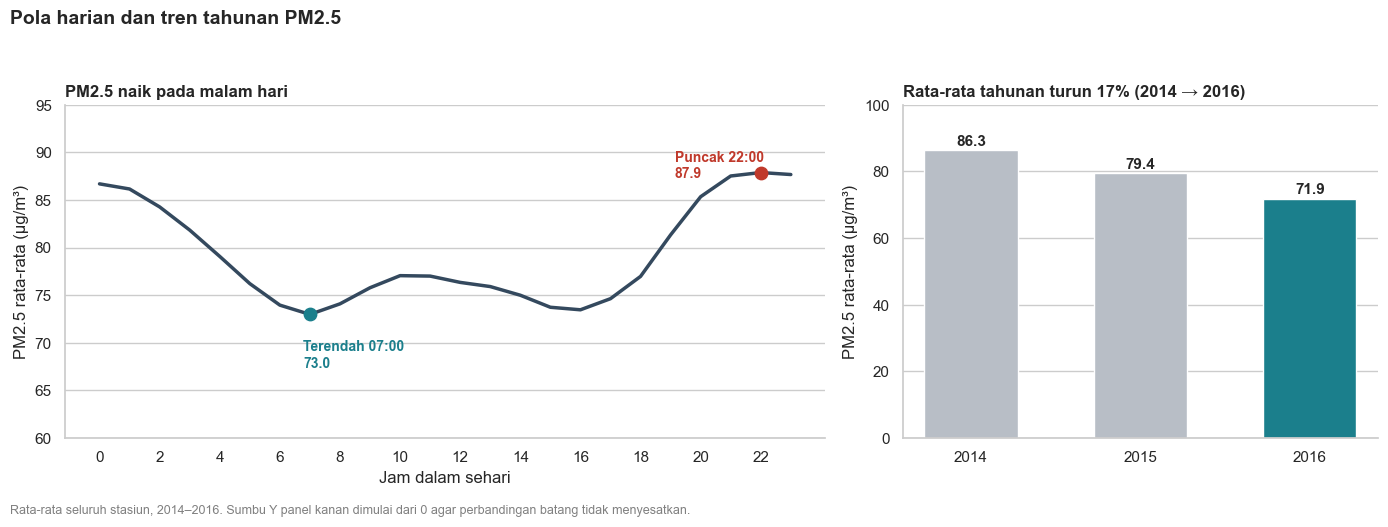

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.6, 1]})

# Panel kiri: pola per jam
ax = axes[0]
ax.plot(hourly_mean.index, hourly_mean.values, color="#34495E", linewidth=2.5)
jam_max, jam_min = hourly_mean.idxmax(), hourly_mean.idxmin()
ax.scatter([jam_max], [hourly_mean.max()], color=C_HIGH, s=80, zorder=3)
ax.scatter([jam_min], [hourly_mean.min()], color=C_LOW, s=80, zorder=3)
ax.annotate(f"Puncak {jam_max:02d}:00\n{hourly_mean.max():.1f}", (jam_max, hourly_mean.max()),
            xytext=(-62, -4), textcoords="offset points", color=C_HIGH, fontsize=10, fontweight="bold")
ax.annotate(f"Terendah {jam_min:02d}:00\n{hourly_mean.min():.1f}", (jam_min, hourly_mean.min()),
            xytext=(-5, -38), textcoords="offset points", color=C_LOW, fontsize=10, fontweight="bold")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Jam dalam sehari")
ax.set_ylabel("PM2.5 rata-rata (µg/m³)")
ax.set_ylim(60, 95)
ax.set_title("PM2.5 naik pada malam hari", loc="left", fontsize=12, fontweight="bold")

# Panel kanan: tren tahunan
ax = axes[1]
ax.bar(yearly_mean.index.astype(str), yearly_mean.values, color=[C_NEUTRAL, C_NEUTRAL, C_LOW], width=0.55)
for x, v in enumerate(yearly_mean.values):
    ax.text(x, v + 1.5, f"{v:.1f}", ha="center", fontsize=11, fontweight="bold")
perubahan = (yearly_mean[2016] / yearly_mean[2014] - 1) * 100
ax.set_title(f"Rata-rata tahunan turun {abs(perubahan):.0f}% (2014 → 2016)", loc="left", fontsize=12, fontweight="bold")
ax.set_ylabel("PM2.5 rata-rata (µg/m³)")
ax.set_ylim(0, 100)

for a in axes:
    a.grid(axis="x", visible=False)
    sns.despine(ax=a)

fig.suptitle("Pola harian dan tren tahunan PM2.5", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, 0.01, "Rata-rata seluruh stasiun, 2014–2016. Sumbu Y panel kanan dimulai dari 0 agar perbandingan batang tidak menyesatkan.",
         fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.03, 1, 0.94])
plt.show()

### Pertanyaan 3:
 Dari variabel cuaca (suhu, tekanan udara, titik embun, curah hujan, kecepatan angin), variabel mana yang memiliki korelasi paling kuat dengan PM2.5 harian, dan dari arah angin mana PM2.5 rata-rata paling tinggi, selama periode 1 Maret 2013 – 28 Februari 2017?


In [24]:
weather_cols = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
corr_weather = daily_df[["PM2.5"] + weather_cols].corr()["PM2.5"].drop("PM2.5").sort_values()
print("Korelasi (Pearson) PM2.5 dengan variabel cuaca:")
print(corr_weather.round(2).to_string())

print("\nPembanding: korelasi PM2.5 dengan polutan lain")
print(daily_df[["PM2.5", "CO", "NO2", "SO2", "O3"]].corr()["PM2.5"].drop("PM2.5").round(2).to_string())

Korelasi (Pearson) PM2.5 dengan variabel cuaca:
WSPM   -0.38
TEMP   -0.15
RAIN   -0.04
PRES    0.05
DEWP    0.08

Pembanding: korelasi PM2.5 dengan polutan lain
CO     0.83
NO2    0.72
SO2    0.51
O3    -0.21


In [25]:
# PM2.5 berdasarkan kelompok kecepatan angin
wind_bins = [0, 1, 2, 3, np.inf]
wind_labels = ["≤ 1 m/s", "1–2 m/s", "2–3 m/s", "> 3 m/s"]
wind_df = daily_df.dropna(subset=["PM2.5", "WSPM"]).copy()
wind_df["kelas_angin"] = pd.cut(wind_df["WSPM"], bins=wind_bins, labels=wind_labels, include_lowest=True)
wind_speed_pm = wind_df.groupby("kelas_angin", observed=True)["PM2.5"].agg(["mean", "count"])
print(wind_speed_pm.round(1))

# PM2.5 berdasarkan arah angin dominan harian
wind_dir_pm = (daily_df.dropna(subset=["PM2.5", "wd"]).groupby("wd")["PM2.5"].mean().sort_values(ascending=False))
print("\nRata-rata PM2.5 per arah angin dominan:")
print(wind_dir_pm.round(1).to_string())

              mean  count
kelas_angin              
≤ 1 m/s     126.80   2184
1–2 m/s      85.70  10511
2–3 m/s      50.90   3438
> 3 m/s      30.60   1283

Rata-rata PM2.5 per arah angin dominan:
wd
E     108.20
ENE   105.80
ESE    99.60
SE     94.70
S      87.70
SSE    87.60
NE     84.70
SSW    80.50
SW     74.20
WSW    71.50
W      70.00
N      66.70
NNE    65.40
NNW    63.00
WNW    60.00
NW     52.70


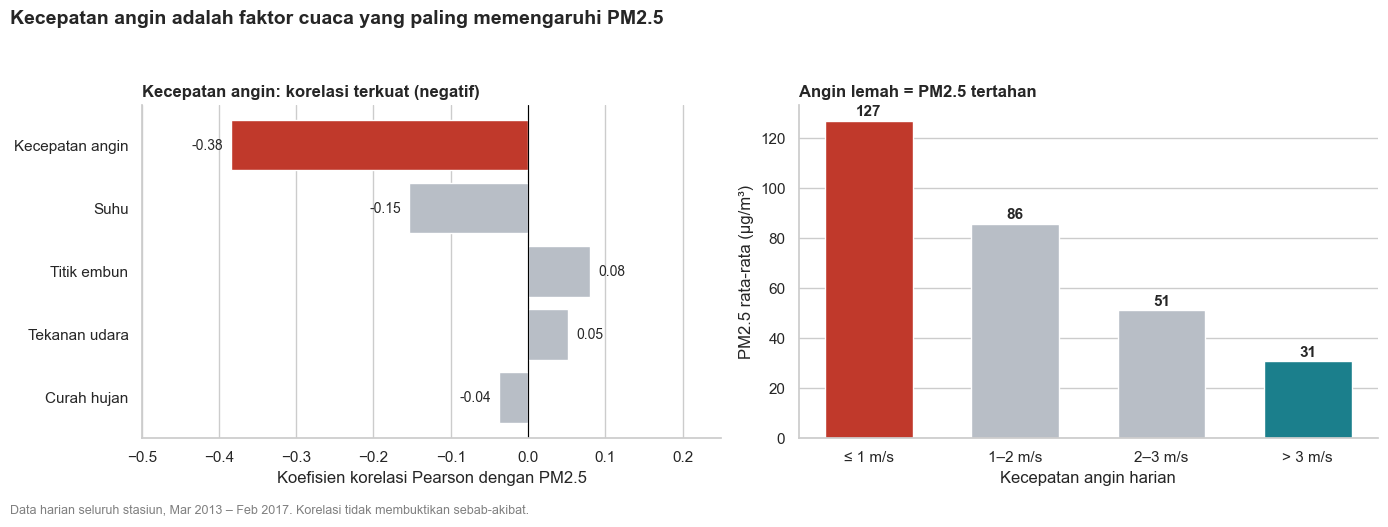

In [26]:
nama_cuaca = {"WSPM": "Kecepatan angin", "TEMP": "Suhu", "RAIN": "Curah hujan",
              "PRES": "Tekanan udara", "DEWP": "Titik embun"}
cw = corr_weather.reindex(corr_weather.abs().sort_values(ascending=True).index)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Panel kiri: korelasi
ax = axes[0]
cols_c = [C_HIGH if abs(v) == cw.abs().max() else C_NEUTRAL for v in cw.values]
ax.barh([nama_cuaca[i] for i in cw.index], cw.values, color=cols_c)
for y, v in enumerate(cw.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), y, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=10)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-0.5, 0.25)
ax.set_xlabel("Koefisien korelasi Pearson dengan PM2.5")
ax.set_title("Kecepatan angin: korelasi terkuat (negatif)", loc="left", fontsize=12, fontweight="bold")

# Panel kanan: PM2.5 per kelas kecepatan angin
ax = axes[1]
cols_w = [C_HIGH, C_NEUTRAL, C_NEUTRAL, C_LOW]
ax.bar(wind_speed_pm.index.astype(str), wind_speed_pm["mean"], color=cols_w, width=0.6)
for x, v in enumerate(wind_speed_pm["mean"]):
    ax.text(x, v + 2, f"{v:.0f}", ha="center", fontsize=11, fontweight="bold")
ax.set_xlabel("Kecepatan angin harian")
ax.set_ylabel("PM2.5 rata-rata (µg/m³)")
ax.set_title("Angin lemah = PM2.5 tertahan", loc="left", fontsize=12, fontweight="bold")

for a in axes:
    sns.despine(ax=a)
axes[0].grid(axis="y", visible=False)
axes[1].grid(axis="x", visible=False)

fig.suptitle("Kecepatan angin adalah faktor cuaca yang paling memengaruhi PM2.5", x=0.01, ha="left",
             fontsize=14, fontweight="bold")
fig.text(0.01, 0.01, "Data harian seluruh stasiun, Mar 2013 – Feb 2017. Korelasi tidak membuktikan sebab-akibat.",
         fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.03, 1, 0.94])
plt.show()

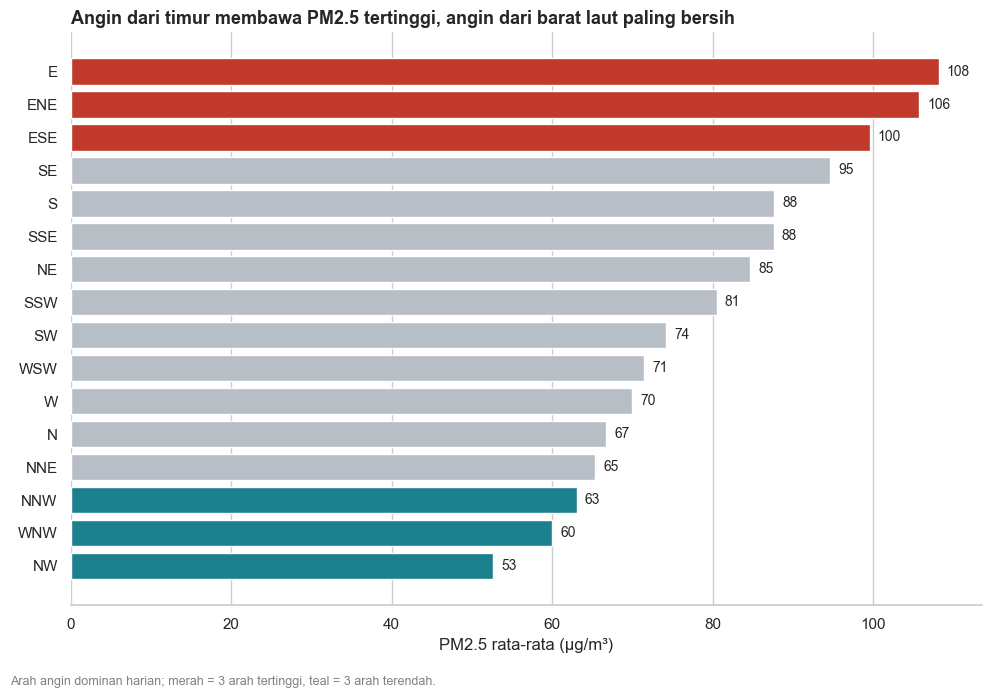

In [27]:
wd_plot = wind_dir_pm.sort_values(ascending=True)
n = len(wd_plot)
cols_d = [C_LOW if i < 3 else (C_HIGH if i >= n - 3 else C_NEUTRAL) for i in range(n)]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(wd_plot.index, wd_plot.values, color=cols_d)
for y, v in enumerate(wd_plot.values):
    ax.text(v + 1, y, f"{v:.0f}", va="center", fontsize=10)
ax.set_xlabel("PM2.5 rata-rata (µg/m³)")
ax.set_title("Angin dari timur membawa PM2.5 tertinggi, angin dari barat laut paling bersih",
             loc="left", fontsize=13, fontweight="bold")
ax.grid(axis="y", visible=False)
sns.despine(left=True)
fig.text(0.01, 0.01, "Arah angin dominan harian; merah = 3 arah tertinggi, teal = 3 arah terendah.",
         fontsize=9, color="gray")
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

**Insight:** (Opsional)
- **Pertanyaan 1:** Perbedaan antarstasiun cukup jelas: stasiun pusat kota (Dongsi, Nongzhanguan, Wanshouxigong) paling tercemar, stasiun pinggiran (Dingling, Huairou, Changping) paling bersih. Semua stasiun melampaui batas tahunan 35 µg/m³ dan melampaui batas harian pada 32–43% hari.
- **Pertanyaan 2:** PM2.5 bersifat musiman (puncak Des/Nov/Feb) dan harian (puncak malam hari sekitar pukul 22:00), dengan tren tahunan yang membaik (2014 → 2016 turun sekitar 17%).
- **Pertanyaan 3:** Angin lemah adalah pemicu utama penumpukan PM2.5, dan angin timur membawa polusi paling tinggi, sementara angin barat laut membersihkan udara.

## Analisis Lanjutan (Opsional)

Teknik yang digunakan adalah **Clustering tanpa algoritma machine learning** berupa **Binning** (`pd.cut`) dan **Manual Grouping** berbasis aturan domain:

1. **Binning kategori kualitas udara harian:** rata-rata PM2.5 harian dikelompokkan ke 6 kategori mengikuti batas indeks kualitas udara China (HJ 633-2012: 35, 75, 115, 150, 250 µg/m³). Tujuannya: melihat seberapa sering tiap stasiun berada pada kondisi tidak sehat, bukan sekadar rata-rata.
2. **Manual grouping stasiun menjadi 3 klaster risiko** (Rendah < 75, Sedang 75–85, Tinggi ≥ 85 µg/m³ rata-rata PM2.5). Tujuannya: menyusun prioritas intervensi berdasarkan aturan bisnis yang sederhana dan mudah dijelaskan ke pemangku kepentingan.
3. **Manual grouping musim** (Dingin: Des–Feb, Semi: Mar–Mei, Panas: Jun–Agu, Gugur: Sep–Nov), ditambah **heatmap stasiun x bulan** untuk menentukan kapan dan di mana intervensi paling dibutuhkan.

#### Binning kategori kualitas udara harian (per stasiun)

In [28]:
bins_aqi = [0, 35, 75, 115, 150, 250, np.inf]
labels_aqi = ["Sangat baik (≤35)", "Baik (35–75)", "Polusi ringan (75–115)",
              "Polusi sedang (115–150)", "Polusi berat (150–250)", "Polusi parah (>250)"]

pm_daily["kategori"] = pd.cut(pm_daily["PM2.5"], bins=bins_aqi, labels=labels_aqi, include_lowest=True)

kategori_all = pm_daily["kategori"].value_counts(normalize=True).reindex(labels_aqi) * 100
print("Distribusi kategori kualitas udara (seluruh stasiun, % hari):")
print(kategori_all.round(1).to_string())

kategori_station = (pd.crosstab(pm_daily["station"], pm_daily["kategori"], normalize="index") * 100)[labels_aqi]
kategori_station["Tidak sehat (≥ ringan)"] = kategori_station[labels_aqi[2:]].sum(axis=1)
kategori_station = kategori_station.sort_values("Tidak sehat (≥ ringan)", ascending=True)
kategori_station.round(1)

Distribusi kategori kualitas udara (seluruh stasiun, % hari):
kategori
Sangat baik (≤35)         29.50
Baik (35–75)              30.10
Polusi ringan (75–115)    18.20
Polusi sedang (115–150)    9.50
Polusi berat (150–250)     9.20
Polusi parah (>250)        3.40


kategori,Sangat baik (≤35),Baik (35–75),Polusi ringan (75–115),Polusi sedang (115–150),Polusi berat (150–250),Polusi parah (>250),Tidak sehat (≥ ringan)
station,,,,,,,
Dingling,41.10,27.00,15.40,7.00,7.20,2.10,31.90
Huairou,35.50,29.80,16.60,8.00,8.60,1.50,34.60
Changping,35.00,28.90,17.40,8.40,8.20,2.10,36.10
Shunyi,29.20,29.80,18.60,9.30,10.10,3.00,41.00
Tiantan,27.30,31.40,18.20,10.10,9.70,3.40,41.30
Guanyuan,26.90,30.80,19.50,10.00,9.10,3.80,42.30
Aotizhongxin,27.00,30.60,18.50,10.70,9.50,3.80,42.40
Wanshouxigong,25.90,31.40,18.80,10.00,9.40,4.50,42.70
Wanliu,27.10,30.10,19.30,10.30,9.30,3.90,42.80


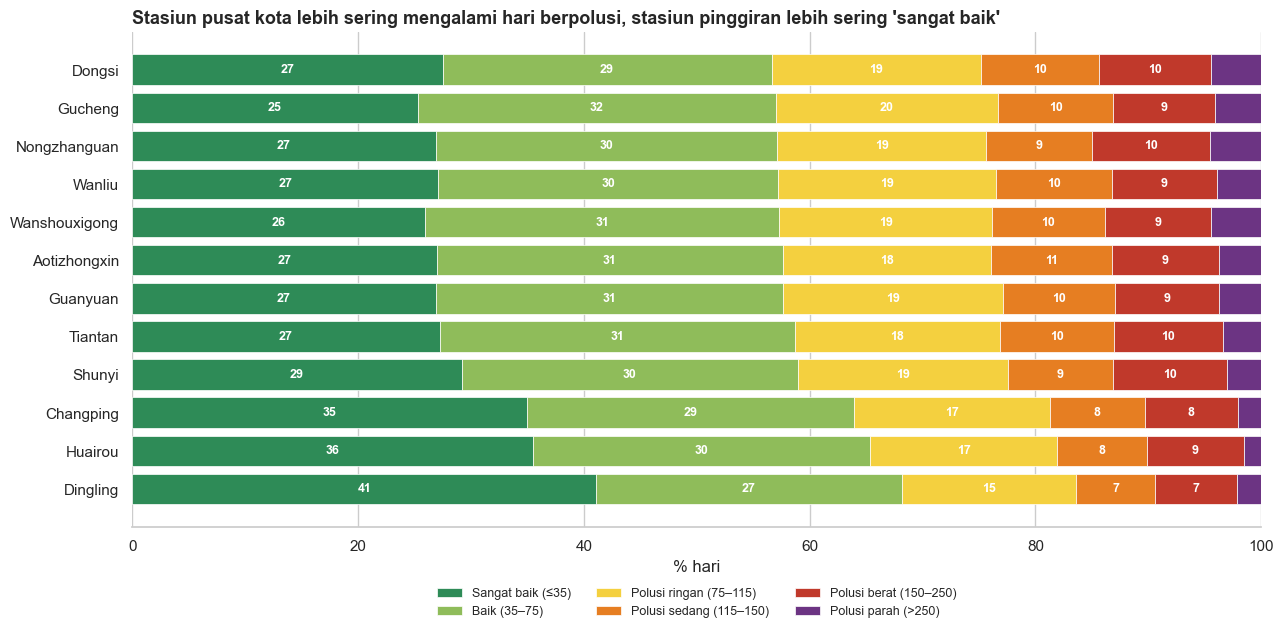

In [29]:
palette_aqi = ["#2E8B57", "#8FBC5A", "#F4D03F", "#E67E22", "#C0392B", "#6C3483"]

fig, ax = plt.subplots(figsize=(13, 6.5))
left = np.zeros(len(kategori_station))
for lab, col in zip(labels_aqi, palette_aqi):
    vals = kategori_station[lab].values
    ax.barh(kategori_station.index, vals, left=left, color=col, label=lab, edgecolor="white", linewidth=0.5)
    for y, (l, v) in enumerate(zip(left, vals)):
        if v >= 6:
            ax.text(l + v / 2, y, f"{v:.0f}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    left += vals
ax.set_xlim(0, 100)
ax.set_xlabel("% hari")
ax.set_title("Stasiun pusat kota lebih sering mengalami hari berpolusi, stasiun pinggiran lebih sering 'sangat baik'",
             loc="left", fontsize=13, fontweight="bold")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False, fontsize=9)
ax.grid(axis="y", visible=False)
sns.despine(left=True)
plt.tight_layout()
plt.show()

#### Manual grouping: klaster risiko stasiun

In [30]:
station_stats["klaster_risiko"] = pd.cut(
    station_stats["mean_pm25"],
    bins=[0, 75, 85, np.inf],
    labels=["Risiko rendah (<75)", "Risiko sedang (75–85)", "Risiko tinggi (≥85)"],
    right=False,
)
cluster_table = station_stats.sort_values("mean_pm25", ascending=False)[["mean_pm25", "persen_melampaui", "klaster_risiko"]]
print(cluster_table.round(1))

print("\nAnggota tiap klaster:")
for k, g in station_stats.groupby("klaster_risiko", observed=True):
    print(f"- {k}: {', '.join(g.sort_values('mean_pm25', ascending=False).index)}")

               mean_pm25  persen_melampaui         klaster_risiko
station                                                          
Dongsi             86.10             43.40    Risiko tinggi (≥85)
Nongzhanguan       85.20             42.90    Risiko tinggi (≥85)
Wanshouxigong      84.90             42.70  Risiko sedang (75–85)
Gucheng            84.00             43.00  Risiko sedang (75–85)
Wanliu             83.50             42.80  Risiko sedang (75–85)
Guanyuan           83.00             42.30  Risiko sedang (75–85)
Aotizhongxin       83.00             42.40  Risiko sedang (75–85)
Tiantan            82.00             41.30  Risiko sedang (75–85)
Shunyi             79.80             41.00  Risiko sedang (75–85)
Changping          71.30             36.10    Risiko rendah (<75)
Huairou            69.40             34.60    Risiko rendah (<75)
Dingling           66.30             31.90    Risiko rendah (<75)

Anggota tiap klaster:
- Risiko rendah (<75): Changping, Huairou, Dingling
-

#### Manual grouping: musim dan heatmap stasiun x bulan

In [31]:
musim_map = {12: "Dingin", 1: "Dingin", 2: "Dingin", 3: "Semi", 4: "Semi", 5: "Semi",
             6: "Panas", 7: "Panas", 8: "Panas", 9: "Gugur", 10: "Gugur", 11: "Gugur"}
full_years = pm_daily[pm_daily["year"].isin([2014, 2015, 2016])].copy()
full_years["musim"] = full_years["month"].map(musim_map)

season_table = full_years.groupby("musim").agg(
    mean_pm25=("PM2.5", "mean"),
    persen_melampaui=("melampaui", lambda s: s.mean() * 100),
).reindex(["Dingin", "Semi", "Panas", "Gugur"])
season_table

,mean_pm25,persen_melampaui
musim,,
Dingin,98.70,47.30
Semi,75.01,39.98
Panas,60.67,31.39
Gugur,82.72,40.84


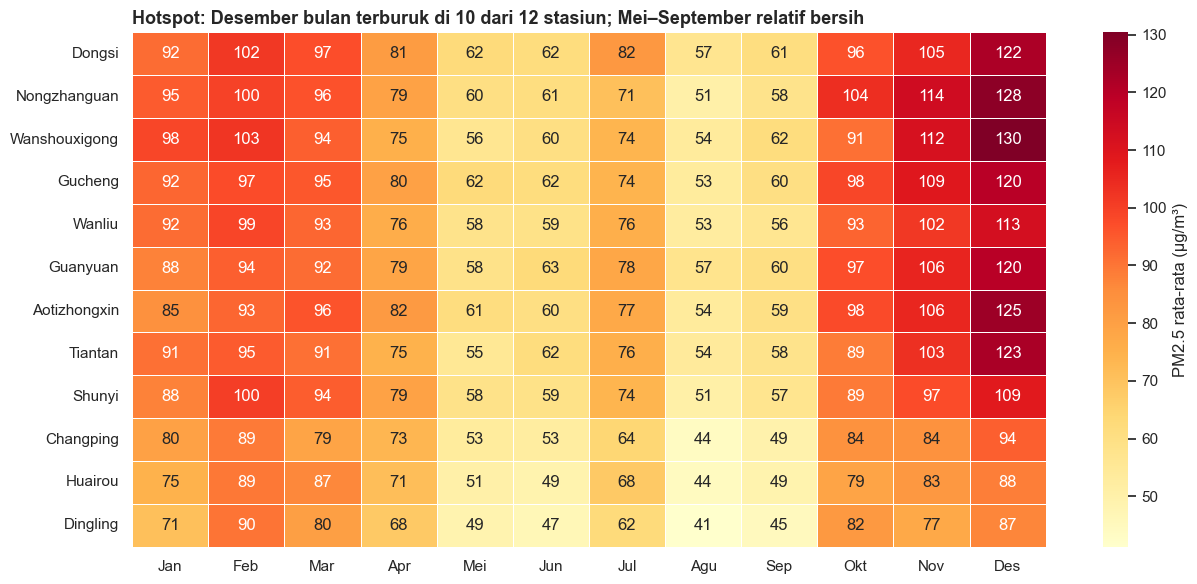

In [32]:
heat = full_years.pivot_table(index="station", columns="month", values="PM2.5", aggfunc="mean")
heat = heat.loc[station_stats.sort_values("mean_pm25", ascending=False).index]
heat.columns = bulan_label

fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(heat, cmap="YlOrRd", annot=True, fmt=".0f", linewidths=0.5, cbar_kws={"label": "PM2.5 rata-rata (µg/m³)"}, ax=ax)
ax.set_title("Hotspot: Desember bulan terburuk di 10 dari 12 stasiun; Mei–September relatif bersih",
             loc="left", fontsize=13, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Sekitar 40% hari (seluruh stasiun) berada pada kategori polusi ringan atau lebih buruk, dan sekitar 13% hari masuk kategori polusi berat/parah (> 150 µg/m³); hanya sekitar 30% hari yang tergolong "sangat baik".
- Klaster risiko tinggi (rata-rata ≥ 85 µg/m³) berisi stasiun Dongsi dan Nongzhanguan; klaster risiko rendah berisi Dingling, Huairou, dan Changping; sisanya (7 stasiun) berada pada risiko sedang. Perbedaan antarstasiun menengah relatif kecil sehingga kebijakan wilayah perkotaan dapat disatukan.
- Musim dingin (Des–Feb) adalah musim paling kritis (rata-rata sekitar 99 µg/m³ dan 47% hari melampaui batas, dibanding sekitar 61 µg/m³ dan 31% pada musim panas); heatmap menunjukkan Desember sebagai bulan terburuk pada 10 dari 12 stasiun (sisanya Februari).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Stasiun dengan rata-rata PM2.5 tertinggi adalah **Dongsi (±86 µg/m³; 43% hari melampaui 75 µg/m³)**, disusul Nongzhanguan dan Wanshouxigong, sedangkan yang terendah adalah **Dingling (±66 µg/m³; 32% hari melampaui)**, diikuti Huairou dan Changping. Selisih tertinggi–terendah sekitar 30%, dan seluruh 12 stasiun berada sekitar 1,9–2,5 kali di atas batas tahunan 35 µg/m³. Polusi bersifat menyeluruh di Beijing, dengan intensitas terbesar di wilayah pusat/barat kota.
- **Conclusion pertanyaan 2:** PM2.5 memuncak pada **Desember (±113 µg/m³), November (±100), dan Februari (±96)** serta terendah pada **Agustus (±51)**. Dalam sehari puncaknya pada **malam hari (±22:00; ±88 µg/m³)** dan terendah pada **pagi–sore (±07:00; ±73 µg/m³)**. Rata-rata tahunan turun dari ±86 (2014) menjadi ±72 µg/m³ (2016), atau sekitar **-17%**, namun masih jauh di atas standar.
- **Conclusion pertanyaan 3:** **Kecepatan angin** adalah variabel cuaca dengan korelasi terkuat terhadap PM2.5 (**r ≈ -0,38**); PM2.5 ±127 µg/m³ saat angin ≤ 1 m/s dibanding ±31 µg/m³ saat angin > 3 m/s. Angin dari **timur (E/ENE/ESE)** membawa PM2.5 tertinggi (±100–108 µg/m³) sedangkan angin **barat laut (NW/WNW/NNW)** paling bersih (±53–63 µg/m³). Suhu, tekanan, titik embun, dan hujan hanya berkorelasi lemah.

**Rekomendasi Action Item:**
- **Prioritaskan intervensi di wilayah pusat/barat kota** (Dongsi, Nongzhanguan, Wanshouxigong, dan stasiun risiko sedang-tinggi lainnya): perketat pengendalian emisi lalu lintas dan pembakaran, dan tambah stasiun/sensor pemantau di sekitarnya.
- **Terapkan kebijakan musiman:** aktifkan pembatasan emisi (industri, kendaraan, pembakaran batu bara/biomassa pemanas) pada **November–Februari**, dengan fokus tertinggi pada Desember.
- **Terapkan peringatan dini berbasis cuaca:** keluarkan siaga ketika prakiraan angin ≤ 1 m/s, terutama bila angin bertiup dari timur; beri imbauan masker dan batasi aktivitas luar ruang bagi kelompok rentan. Kegiatan luar ruang sebaiknya dijadwalkan pada pagi hingga sore hari, bukan malam.
- **Pertahankan kebijakan yang telah menurunkan PM2.5 (2014→2016)** dan tetapkan target penurunan bertahap menuju standar tahunan 35 µg/m³.
- **Catatan keterbatasan:** korelasi tidak sama dengan sebab-akibat; data berasal dari 12 stasiun selama 4 tahun sehingga hasil perlu diperbarui dengan data terbaru sebelum dijadikan kebijakan.